In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [4]:
import os
base = '/content/drive/MyDrive/Desafio.Final_DMD'
os.makedirs(f'{base}/datasets', exist_ok=True)
os.makedirs(f'{base}/output', exist_ok=True)
os.chdir(base)
print(os.listdir('datasets'))

['comerciantes_mercado.csv', 'quiebra_mercado.csv', 'transacciones_mercado.csv']


In [5]:
!pip install -q mlxtend
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns

In [6]:
trans = pd.read_csv('datasets/transacciones_mercado.csv')
com = pd.read_csv('datasets/comerciantes_mercado.csv')
quie = pd.read_csv('datasets/quiebra_mercado.csv')
for n, d in [('trans', trans), ('com', com), ('quie', quie)]:
    print(n, d.shape)

trans (1000, 6)
com (500, 19)
quie (800, 20)


In [7]:
#COMEZAMOS CON EL EDA
print(trans.shape)
print(trans.dtypes)
print("\nNulos:\n", trans.isnull().sum())
print("\nDuplicados:", trans.duplicated().sum())
display(trans.head())
display(trans[['total_usd']].describe())
print("\nMétodos de pago:\n", trans['metodo_pago'].value_counts())

# Productos por transacción
trans['n_productos'] = trans['productos'].str.split(';').apply(len)
print("\nProductos por transacción:\n", trans['n_productos'].describe())

# Productos únicos
todos = trans['productos'].str.split(';').explode().str.strip()
print("\nProductos únicos:", todos.nunique())
print(todos.value_counts().head(15))

(1000, 6)
transaccion_id     object
fecha              object
hora               object
metodo_pago        object
total_usd         float64
productos          object
dtype: object

Nulos:
 transaccion_id    0
fecha             0
hora              0
metodo_pago       0
total_usd         0
productos         0
dtype: int64

Duplicados: 0


,transaccion_id,fecha,hora,metodo_pago,total_usd,productos
0,T0001,2026-07-26,13:30,Efectivo,12.61,Maíz Blanco; Queso Fresco; Chicharrón; Loroco;...
1,T0002,2026-07-03,12:00,Efectivo,40.60,Maíz Blanco; Queso Fresco; Chicharrón; Loroco;...
2,T0003,2026-07-05,17:30,Cheque,13.22,Yuca; Chicharrón; Repollo; Tomate; Chile Verde...
3,T0004,2026-06-20,09:15,Tarjeta,22.26,Yuca; Chicharrón; Repollo; Tomate; Chile Verde
4,T0005,2026-06-19,15:45,Efectivo,14.23,Frijol Rojo; Queso Fresco; Crema Salvadoreña; ...


,total_usd
count,1000.000000
mean,23.030370
std,9.913892
min,3.800000
25%,15.335000
50%,21.715000
75%,29.500000
max,62.880000



Métodos de pago:
 metodo_pago
Efectivo         817
Tarjeta          109
Transferencia     49
Cheque            25
Name: count, dtype: int64

Productos por transacción:
 count    1000.000000
mean        6.183000
std         1.835451
min         3.000000
25%         5.000000
50%         6.000000
75%         7.000000
max        12.000000
Name: n_productos, dtype: float64

Productos únicos: 48
productos
Tomate               554
Repollo              406
Chile Verde          350
Café en Grano        331
Queso Fresco         302
Frijol Rojo          246
Cebolla              244
Huevos               239
Chicharrón           232
Sal                  225
Arroz                222
Aceite               217
Yuca                 188
Crema Salvadoreña    183
Pan Francés          181
Name: count, dtype: int64


In [8]:
print(com.shape)
print(com.dtypes)
print("\nNulos:\n", com.isnull().sum())
print("\nDuplicados:", com.duplicated().sum())
display(com.describe().T)
for c in ['rubro', 'ubicacion', 'nivel_educativo', 'vende_online', 'acepta_tarjeta']:
    print(f"\n{c}:\n", com[c].value_counts())

print("\nantiguedad_local > anios_operacion:", (com['antiguedad_local'] > com['anios_operacion']).sum())

(500, 19)
comerciante_id         object
nombre_negocio         object
rubro                  object
anios_operacion         int64
antiguedad_local        int64
ubicacion              object
empleados               int64
ingreso_mensual_usd     int64
egreso_mensual_usd      int64
m2_local                int64
tiene_almacen          object
vende_online           object
acepta_tarjeta         object
horario_extendido      object
ahorro_previo_usd       int64
deuda_actual_usd        int64
quejas_clientes_3m      int64
edad_comerciante        int64
nivel_educativo        object
dtype: object

Nulos:
 comerciante_id         0
nombre_negocio         0
rubro                  0
anios_operacion        0
antiguedad_local       0
ubicacion              0
empleados              0
ingreso_mensual_usd    0
egreso_mensual_usd     0
m2_local               0
tiene_almacen          0
vende_online           0
acepta_tarjeta         0
horario_extendido      0
ahorro_previo_usd      0
deuda_actual_usd      

,count,mean,std,min,25%,50%,75%,max
anios_operacion,500.0,10.866,9.031899,1.0,3.00,8.0,18.00,40.0
antiguedad_local,500.0,4.020,3.564971,1.0,1.00,3.0,5.00,18.0
empleados,500.0,2.200,1.656952,0.0,1.00,2.0,3.00,10.0
ingreso_mensual_usd,500.0,2540.594,972.353644,608.0,1826.75,2339.0,3092.25,5852.0
egreso_mensual_usd,500.0,1778.586,689.781260,472.0,1249.00,1688.0,2208.50,4246.0
m2_local,500.0,19.144,5.788807,5.0,15.00,19.0,23.00,39.0
ahorro_previo_usd,500.0,5439.468,3853.683984,482.0,2543.00,4394.5,7423.00,24284.0
deuda_actual_usd,500.0,1170.386,1314.882148,1.0,333.75,601.5,1463.00,4959.0
quejas_clientes_3m,500.0,1.370,1.922627,0.0,0.00,1.0,2.00,15.0
edad_comerciante,500.0,43.690,11.109669,19.0,36.00,44.0,51.00,75.0



rubro:
 rubro
Abarrotes            92
Frutas y Verduras    78
Misceláneos          68
Textiles             66
Carnes               55
Panadería            50
Lácteos              46
Comida Rápida        45
Name: count, dtype: int64

ubicacion:
 ubicacion
Norte     117
Centro    111
Oeste      97
Este       92
Sur        83
Name: count, dtype: int64

nivel_educativo:
 nivel_educativo
Básico      171
Primaria    143
Medio       126
Superior     60
Name: count, dtype: int64

vende_online:
 vende_online
No    358
Sí    142
Name: count, dtype: int64

acepta_tarjeta:
 acepta_tarjeta
No    329
Sí    171
Name: count, dtype: int64

antiguedad_local > anios_operacion: 0


In [9]:
print(quie.shape)
print(quie.dtypes)
print("\nNulos:\n", quie.isnull().sum())
print("\nDuplicados (registro_id):", quie['registro_id'].duplicated().sum())
display(quie.describe().T)
print("\nBalance de clases:\n", quie['quiebra_6m'].value_counts(normalize=True))
for c in ['rubro', 'ubicacion', 'tiene_seguro', 'recibio_credito_pandemia', 'nivel_educativo']:
    print(f"\n{c}:\n", quie[c].value_counts())

(800, 20)
registro_id                        object
comerciante_id                     object
anios_operacion                     int64
rubro                              object
ubicacion                          object
ingreso_promedio_3m_usd             int64
variacion_ingreso_pct             float64
deuda_actual_usd                    int64
ahorro_previo_usd                   int64
tiene_seguro                       object
recibio_credito_pandemia           object
pandemia_caida_ventas_pct         float64
post_pandemia_recuperacion_pct    float64
edad_comerciante                    int64
nivel_educativo                    object
numero_empleados                    int64
ventas_diarias_promedio             int64
clientes_diarios                    int64
margen_ganancia_pct               float64
quiebra_6m                          int64
dtype: object

Nulos:
 registro_id                       0
comerciante_id                    0
anios_operacion                   0
rubro              

,count,mean,std,min,25%,50%,75%,max
anios_operacion,800.0,10.882500,9.706001,1.00,3.0000,8.000,18.0000,40.00
ingreso_promedio_3m_usd,800.0,2496.103750,1125.383801,432.00,1661.0000,2264.500,3181.2500,7191.00
variacion_ingreso_pct,800.0,0.210025,25.098341,-49.57,-19.6400,3.270,20.8225,39.92
deuda_actual_usd,800.0,1166.590000,1332.851058,1.00,310.7500,589.500,1635.0000,4959.00
ahorro_previo_usd,800.0,5504.323750,4156.597967,482.00,2546.0000,4323.000,7397.0000,24284.00
pandemia_caida_ventas_pct,800.0,51.934000,17.494768,20.22,37.3500,51.045,66.1950,89.96
post_pandemia_recuperacion_pct,800.0,63.503325,19.068451,-28.31,47.9375,65.160,79.7600,94.93
edad_comerciante,800.0,43.357500,11.426741,19.00,35.0000,44.000,51.0000,74.00
numero_empleados,800.0,2.140000,1.664741,0.00,1.0000,2.000,3.0000,10.00
ventas_diarias_promedio,800.0,5.358750,3.258961,2.00,3.0000,4.000,7.0000,21.00



Balance de clases:
 quiebra_6m
0    0.7675
1    0.2325
Name: proportion, dtype: float64

rubro:
 rubro
Abarrotes            156
Frutas y Verduras    119
Textiles             114
Misceláneos          103
Carnes                90
Comida Rápida         83
Panadería             70
Lácteos               65
Name: count, dtype: int64

ubicacion:
 ubicacion
Centro    185
Norte     163
Oeste     155
Este      153
Sur       144
Name: count, dtype: int64

tiene_seguro:
 tiene_seguro
No    680
Sí    120
Name: count, dtype: int64

recibio_credito_pandemia:
 recibio_credito_pandemia
No    566
Sí    234
Name: count, dtype: int64

nivel_educativo:
 nivel_educativo
Básico      248
Primaria    240
Medio       214
Superior     98
Name: count, dtype: int64


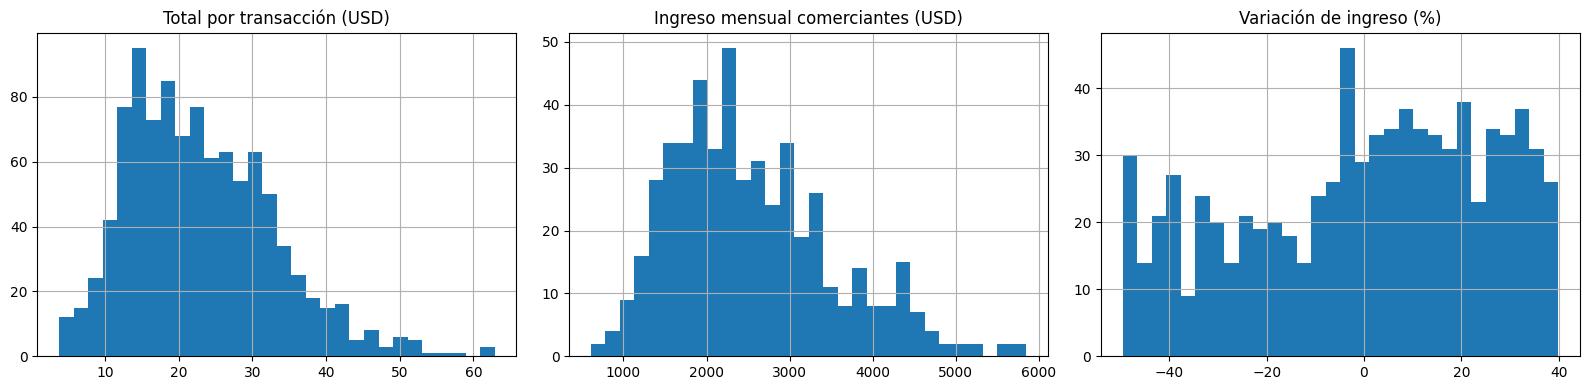

In [10]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
trans['total_usd'].hist(ax=ax[0], bins=30); ax[0].set_title('Total por transacción (USD)')
com['ingreso_mensual_usd'].hist(ax=ax[1], bins=30); ax[1].set_title('Ingreso mensual comerciantes (USD)')
quie['variacion_ingreso_pct'].hist(ax=ax[2], bins=30); ax[2].set_title('Variación de ingreso (%)')
plt.tight_layout(); plt.show()

COMENZANDO CON EL RETO 1: REGLAS DE ASOCIACIÓN

In [11]:
from mlxtend.preprocessing import TransactionEncoder
from mlxtend.frequent_patterns import apriori, association_rules

lista = trans['productos'].apply(lambda x: [p.strip() for p in x.split(';')]).tolist()

te = TransactionEncoder()
df_te = pd.DataFrame(te.fit(lista).transform(lista), columns=te.columns_)
print(df_te.shape)

freq = apriori(df_te, min_support=0.05, use_colnames=True)
freq['k'] = freq['itemsets'].apply(len)
print("Itemsets frecuentes:", len(freq))
print(freq['k'].value_counts().sort_index())

(1000, 48)
Itemsets frecuentes: 1465
k
1      32
2     127
3     257
4     331
5     313
6     227
7     122
8      45
9      10
10      1
Name: count, dtype: int64


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [12]:
reglas = association_rules(freq, metric='confidence', min_threshold=0.30)

reglas = reglas.sort_values('lift', ascending=False).reset_index(drop=True)
print("Reglas:", len(reglas))

cols = ['antecedents', 'consequents', 'support', 'confidence', 'lift', 'conviction', 'leverage']
top10 = reglas[cols].head(10)
display(top10)

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Reglas: 57812


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,antecedents,consequents,support,confidence,lift,conviction,leverage
0,"(Aceite, Jabón Lavadero, Café en Grano)","(Detergente, Azúcar)",0.065,0.984848,14.699231,61.578000,0.060578
1,"(Detergente, Azúcar)","(Aceite, Jabón Lavadero, Café en Grano)",0.065,0.970149,14.699231,31.289000,0.060578
2,"(Jabón Lavadero, Huevos)","(Detergente, Azúcar, Aceite)",0.064,0.984615,14.695752,60.645000,0.059645
3,"(Detergente, Azúcar)","(Aceite, Jabón Lavadero, Huevos)",0.064,0.955224,14.695752,20.881667,0.059645
4,"(Detergente, Jabón Lavadero, Sal)","(Azúcar, Aceite, Café en Grano)",0.064,0.984615,14.695752,60.645000,0.059645
5,"(Detergente, Café en Grano, Sal)","(Azúcar, Aceite, Jabón Lavadero)",0.064,0.984615,14.695752,60.645000,0.059645
6,"(Azúcar, Aceite, Jabón Lavadero)","(Detergente, Café en Grano, Sal)",0.064,0.955224,14.695752,20.881667,0.059645
7,"(Aceite, Jabón Lavadero, Café en Grano, Sal)","(Detergente, Azúcar)",0.064,0.984615,14.695752,60.645000,0.059645
8,"(Jabón Lavadero, Café en Grano, Sal)","(Detergente, Azúcar, Aceite)",0.064,0.984615,14.695752,60.645000,0.059645
9,"(Aceite, Jabón Lavadero, Huevos)","(Detergente, Azúcar)",0.064,0.984615,14.695752,60.645000,0.059645


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [13]:
import warnings; warnings.filterwarnings('ignore')

reglas['n_ant'] = reglas['antecedents'].apply(len)
reglas['n_con'] = reglas['consequents'].apply(len)
reglas['regla'] = (reglas['antecedents'].apply(lambda s: ' + '.join(sorted(s)))
                   + '  →  ' + reglas['consequents'].apply(lambda s: ' + '.join(sorted(s))))

#Itemset más grande encontrado
print(freq.sort_values('k', ascending=False).head(3)[['itemsets', 'support']])

#Antecedente de hasta 2 productos y 1 consecuente
simples = reglas[(reglas.n_ant <= 2) & (reglas.n_con == 1)].reset_index(drop=True)
print("Reglas simples:", len(simples))
display(simples[['regla', 'support', 'confidence', 'lift', 'conviction', 'leverage']].head(10))

#Solo pares (1 → 1), para ver el resto de asociaciones
pares = reglas[(reglas.n_ant == 1) & (reglas.n_con == 1)].reset_index(drop=True)
print("Pares:", len(pares))
display(pares[['regla', 'support', 'confidence', 'lift']].head(10))

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

                                               itemsets  support
1464  (Aceite, Frijol Rojo, Detergente, Leche, Café ...    0.056
1463  (Frijol Rojo, Detergente, Leche, Café en Grano...    0.056
1454  (Aceite, Frijol Rojo, Detergente, Leche, Café ...    0.057
Reglas simples: 954


,regla,support,confidence,lift,conviction,leverage
0,Huevos + Jabón Lavadero → Azúcar,0.065,1.000000,12.048193,inf,0.059605
1,Frijol Rojo + Jabón Lavadero → Azúcar,0.065,1.000000,12.048193,inf,0.059605
2,Aceite + Frijol Rojo → Azúcar,0.066,0.985075,11.868369,61.4390,0.060439
3,Huevos + Leche → Azúcar,0.064,0.984615,11.862836,59.6050,0.058605
4,Aceite + Café en Grano → Azúcar,0.067,0.971014,11.698970,31.6365,0.061273
5,Aceite + Leche → Azúcar,0.066,0.970588,11.693834,31.1780,0.060356
6,Aceite + Huevos → Azúcar,0.066,0.970588,11.693834,31.1780,0.060356
7,Detergente + Huevos → Azúcar,0.065,0.970149,11.688545,30.7195,0.059439
8,Detergente + Frijol Rojo → Azúcar,0.065,0.970149,11.688545,30.7195,0.059439
9,Leche + Sal → Azúcar,0.065,0.970149,11.688545,30.7195,0.059439


Pares: 212


,regla,support,confidence,lift
0,Pollo Entero → Comino,0.075,0.833333,10.162602
1,Comino → Pollo Entero,0.075,0.914634,10.162602
2,Güisquil → Comino,0.075,0.815217,9.941676
3,Comino → Güisquil,0.075,0.914634,9.941676
4,Pollo Entero → Güisquil,0.077,0.855556,9.299517
5,Güisquil → Pollo Entero,0.077,0.836957,9.299517
6,Maíz Blanco → Loroco,0.122,0.910448,7.003444
7,Loroco → Maíz Blanco,0.122,0.938462,7.003444
8,Jabón Lavadero → Detergente,0.114,0.844444,6.546081
9,Detergente → Jabón Lavadero,0.114,0.883721,6.546081


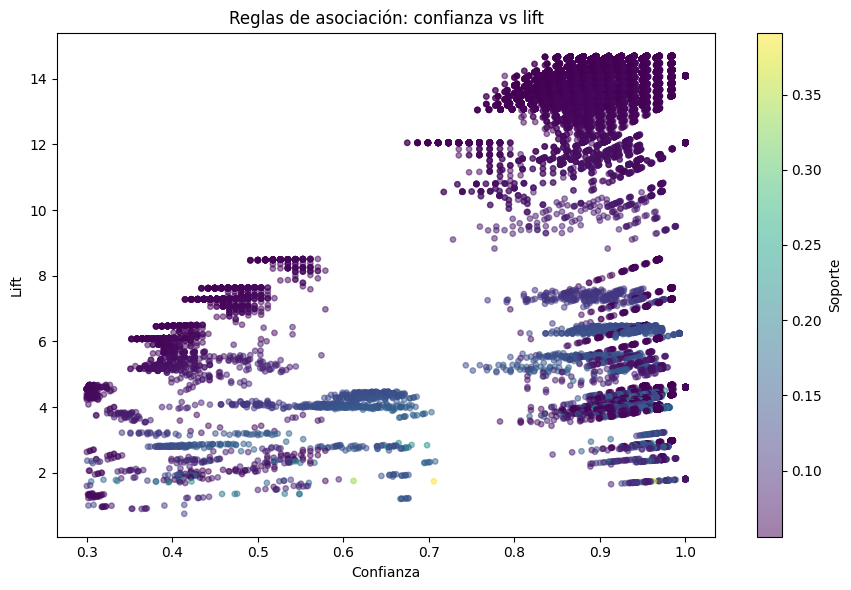

In [14]:
plt.figure(figsize=(9, 6))
sc = plt.scatter(reglas['confidence'], reglas['lift'], c=reglas['support'],
                 cmap='viridis', alpha=0.5, s=15)
plt.colorbar(sc, label='Soporte')
plt.xlabel('Confianza'); plt.ylabel('Lift')
plt.title('Reglas de asociación: confianza vs lift')
plt.tight_layout(); plt.show()

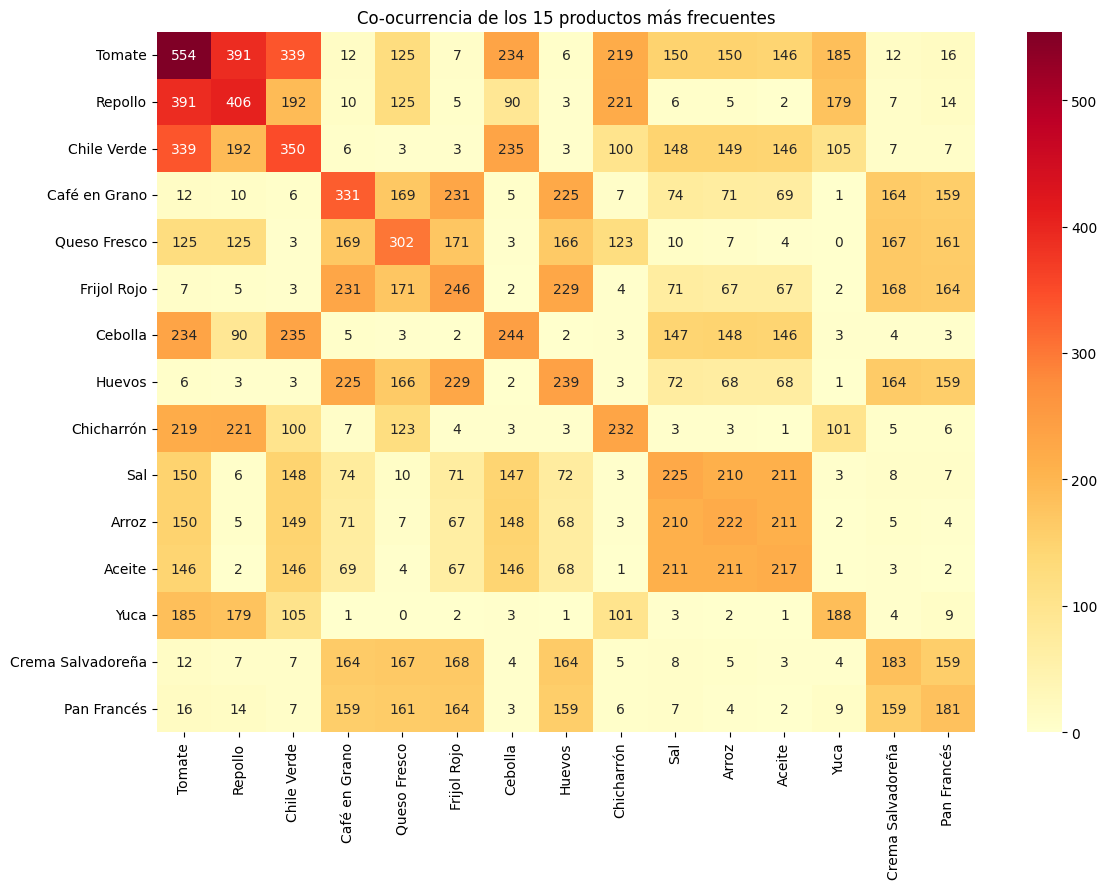

In [15]:
top15 = df_te.sum().sort_values(ascending=False).head(15).index
X = df_te[top15].astype(int)
co = X.T.dot(X)

plt.figure(figsize=(12, 9))
sns.heatmap(co, annot=True, fmt='d', cmap='YlOrRd')
plt.title('Co-ocurrencia de los 15 productos más frecuentes')
plt.tight_layout(); plt.show()

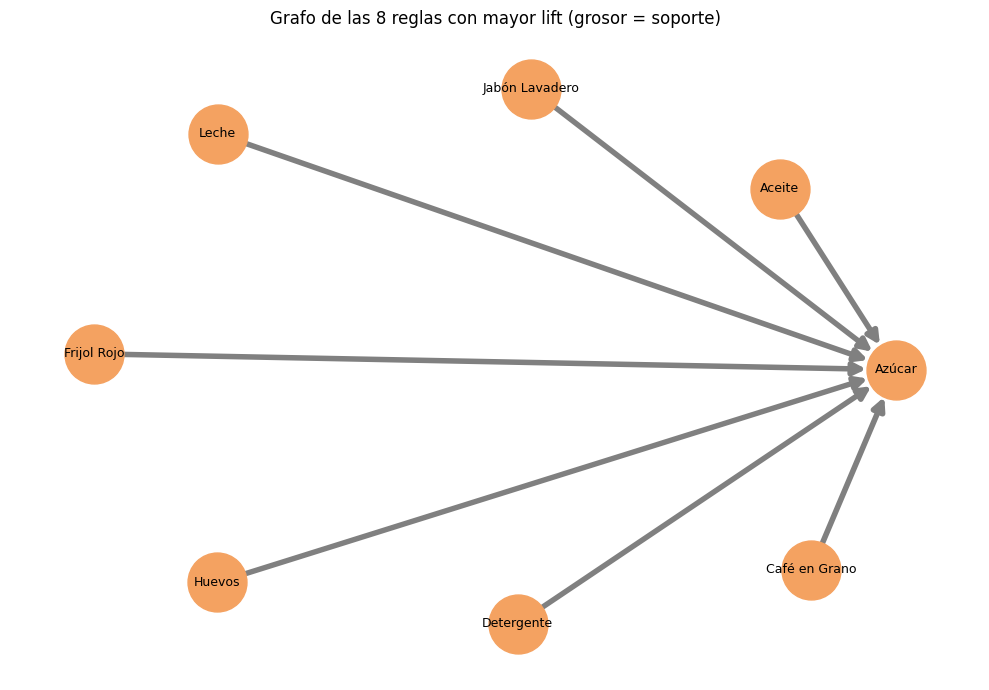

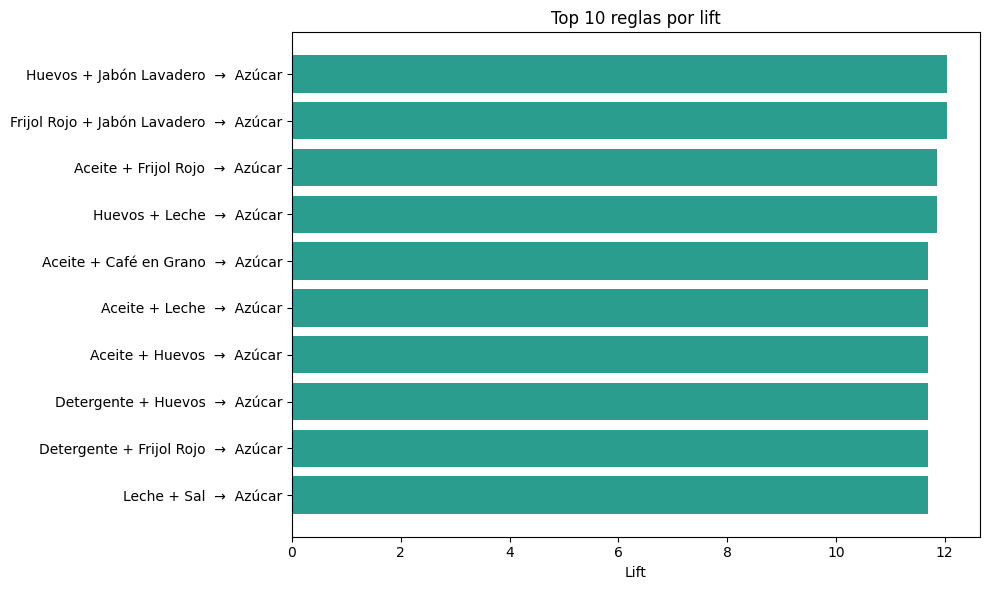

In [16]:
import networkx as nx

top8 = simples.head(8)
G = nx.DiGraph()
for _, r in top8.iterrows():
    for a in r['antecedents']:
        for c in r['consequents']:
            G.add_edge(a, c, weight=r['support'])

anchos = [G[u][v]['weight'] * 60 for u, v in G.edges()]
plt.figure(figsize=(10, 7))
pos = nx.spring_layout(G, seed=42, k=1.2)
nx.draw_networkx(G, pos, node_color='#f4a261', node_size=1800, font_size=9,
                 width=anchos, arrowsize=18, edge_color='gray')
plt.title('Grafo de las 8 reglas con mayor lift (grosor = soporte)')
plt.axis('off'); plt.tight_layout(); plt.show()

# Gráfico obligatorio: output/top_lift.png
t = simples.head(10).iloc[::-1]
plt.figure(figsize=(10, 6))
plt.barh(t['regla'], t['lift'], color='#2a9d8f')
plt.xlabel('Lift'); plt.title('Top 10 reglas por lift')
plt.tight_layout()
plt.savefig('output/top_lift.png', dpi=150)
plt.show()

CELDA PARA COMPARAR EL TICKET CON Y SIN CASDA COMBO

In [17]:
combos = {
    'Limpieza (Detergente + Jabón)': ['Detergente', 'Jabón Lavadero'],
    'Masa (Maíz Blanco + Loroco)': ['Maíz Blanco', 'Loroco'],
    'Sopa (Pollo + Comino + Güisquil)': ['Pollo Entero', 'Comino', 'Güisquil'],
}
for nombre, prods in combos.items():
    mask = df_te[prods].all(axis=1).values
    con, sin = trans.loc[mask, 'total_usd'], trans.loc[~mask, 'total_usd']
    print(f"{nombre}: {mask.sum()} transacciones | ticket con combo ${con.mean():.2f} vs sin combo ${sin.mean():.2f}")

Limpieza (Detergente + Jabón): 114 transacciones | ticket con combo $27.17 vs sin combo $22.50
Masa (Maíz Blanco + Loroco): 122 transacciones | ticket con combo $24.04 vs sin combo $22.89
Sopa (Pollo + Comino + Güisquil): 73 transacciones | ticket con combo $25.73 vs sin combo $22.82


RETO 2: K-MEANS

In [18]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, calinski_harabasz_score, davies_bouldin_score
import warnings; warnings.filterwarnings('ignore')

df = com.drop(columns=['comerciante_id', 'nombre_negocio']).copy()

# Binarias Sí/No -> 1/0
binarias = ['tiene_almacen', 'vende_online', 'acepta_tarjeta', 'horario_extendido']
for c in binarias:
    df[c] = df[c].map({'Sí': 1, 'No': 0})

# One-hot para categóricas
df_enc = pd.get_dummies(df, columns=['rubro', 'ubicacion', 'nivel_educativo'], dtype=int)

# Escalar solo las numéricas continuas
num_cols = ['anios_operacion', 'antiguedad_local', 'empleados', 'ingreso_mensual_usd',
            'egreso_mensual_usd', 'm2_local', 'ahorro_previo_usd', 'deuda_actual_usd',
            'quejas_clientes_3m', 'edad_comerciante']
df_scaled = df_enc.copy()
df_scaled[num_cols] = StandardScaler().fit_transform(df_enc[num_cols])

X = df_scaled.values
print("Matriz X:", X.shape)
print("Nulos:", np.isnan(X).sum())

Matriz X: (500, 31)
Nulos: 0


In [19]:
ks = list(range(1, 11))
inercias, sil, ch, db = [], {}, {}, {}

for k in ks:
    km = KMeans(n_clusters=k, init='k-means++', n_init=10, random_state=42).fit(X)
    inercias.append(km.inertia_)
    if k >= 2:
        sil[k] = silhouette_score(X, km.labels_)
        ch[k] = calinski_harabasz_score(X, km.labels_)
        db[k] = davies_bouldin_score(X, km.labels_)

# Codo con segunda derivada
d2 = np.diff(inercias, n=2)
k_codo = int(np.argmax(d2) + 2)
k_sil = max(sil, key=sil.get)
k_ch = max(ch, key=ch.get)
k_db = min(db, key=db.get)

print(f"K óptimo -> Codo: {k_codo} | Silueta: {k_sil} | Calinski-Harabasz: {k_ch} | Davies-Bouldin: {k_db}")
tabla = pd.DataFrame({'silhouette': sil, 'calinski_harabasz': ch, 'davies_bouldin': db}).round(3)
display(tabla)

K óptimo -> Codo: 2 | Silueta: 2 | Calinski-Harabasz: 2 | Davies-Bouldin: 10


,silhouette,calinski_harabasz,davies_bouldin
2,0.170,97.583,2.170
3,0.132,66.552,2.359
4,0.121,55.943,2.221
5,0.102,50.091,2.426
6,0.094,46.176,2.288
7,0.102,42.100,2.218
8,0.069,39.717,2.319
9,0.077,37.268,2.247
10,0.071,35.198,2.167


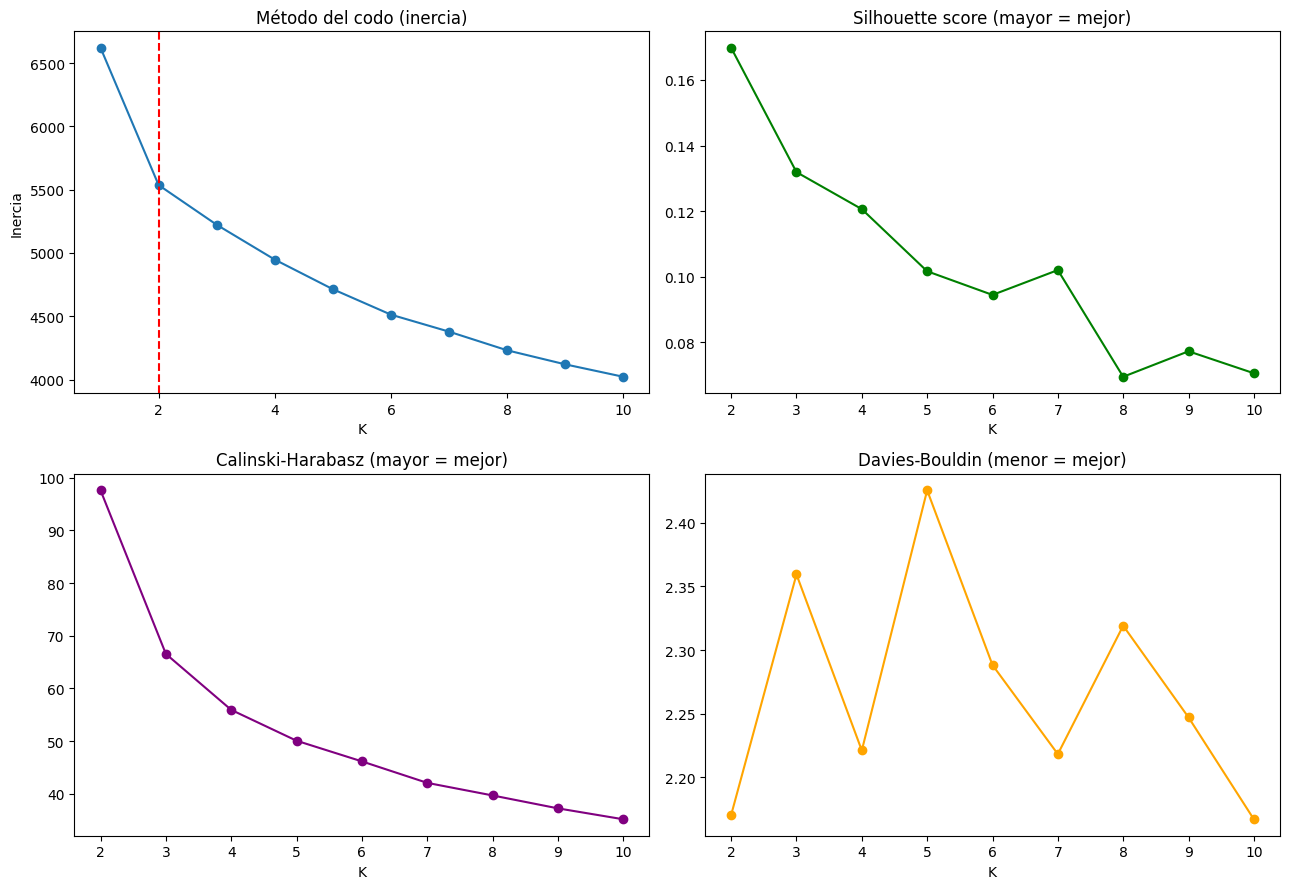

In [20]:
fig, ax = plt.subplots(2, 2, figsize=(13, 9))

ax[0, 0].plot(ks, inercias, 'o-'); ax[0, 0].axvline(k_codo, color='r', ls='--')
ax[0, 0].set_title('Método del codo (inercia)'); ax[0, 0].set_xlabel('K'); ax[0, 0].set_ylabel('Inercia')

ax[0, 1].plot(list(sil), list(sil.values()), 'o-', color='g')
ax[0, 1].set_title('Silhouette score (mayor = mejor)'); ax[0, 1].set_xlabel('K')

ax[1, 0].plot(list(ch), list(ch.values()), 'o-', color='purple')
ax[1, 0].set_title('Calinski-Harabasz (mayor = mejor)'); ax[1, 0].set_xlabel('K')

ax[1, 1].plot(list(db), list(db.values()), 'o-', color='orange')
ax[1, 1].set_title('Davies-Bouldin (menor = mejor)'); ax[1, 1].set_xlabel('K')

plt.tight_layout(); plt.show()

K sugerido por Gap Statistic: 2


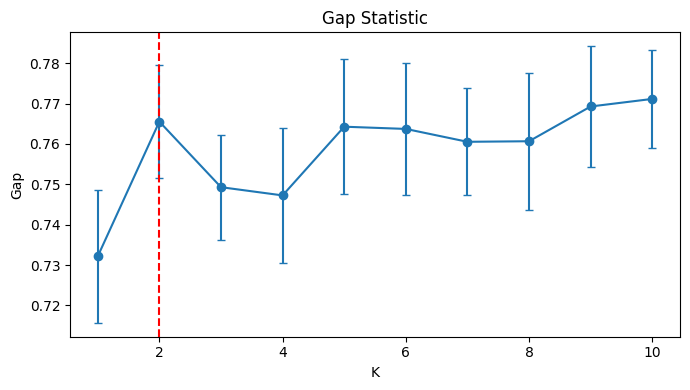

In [21]:
def gap_statistic(X, ks, B=10, seed=42):
    rng = np.random.default_rng(seed)
    mins, maxs = X.min(axis=0), X.max(axis=0)
    gaps, sks = [], []
    for k in ks:
        log_wk = np.log(KMeans(n_clusters=k, n_init=10, random_state=42).fit(X).inertia_)
        log_wkb = []
        for _ in range(B):
            Xb = rng.uniform(mins, maxs, size=X.shape)
            log_wkb.append(np.log(KMeans(n_clusters=k, n_init=5, random_state=42).fit(Xb).inertia_))
        gaps.append(np.mean(log_wkb) - log_wk)
        sks.append(np.std(log_wkb) * np.sqrt(1 + 1 / B))
    return np.array(gaps), np.array(sks)

ks_gap = list(range(1, 11))
gaps, sks = gap_statistic(X, ks_gap)

# Regla de Tibshirani: menor K tal que Gap(k) >= Gap(k+1) - s(k+1)
k_gap = next((k for i, k in enumerate(ks_gap[:-1]) if gaps[i] >= gaps[i+1] - sks[i+1]), ks_gap[-1])
print("K sugerido por Gap Statistic:", k_gap)

plt.figure(figsize=(7, 4))
plt.errorbar(ks_gap, gaps, yerr=sks, fmt='o-', capsize=3)
plt.axvline(k_gap, color='r', ls='--')
plt.xlabel('K'); plt.ylabel('Gap'); plt.title('Gap Statistic')
plt.tight_layout(); plt.show()

In [22]:
comparativa = pd.DataFrame({
    'Método': ['Codo (2ª derivada)', 'Silueta', 'Calinski-Harabasz', 'Davies-Bouldin', 'Gap Statistic'],
    'K sugerido': [k_codo, k_sil, k_ch, k_db, k_gap]
})
display(comparativa)

,Método,K sugerido
0,Codo (2ª derivada),2
1,Silueta,2
2,Calinski-Harabasz,2
3,Davies-Bouldin,10
4,Gap Statistic,2


In [23]:
K_FINAL = 3
km = KMeans(n_clusters=K_FINAL, init='k-means++', n_init=10, random_state=42).fit(X)
df['cluster'] = km.labels_

df['margen_usd'] = df['ingreso_mensual_usd'] - df['egreso_mensual_usd']
perfil = df.groupby('cluster').agg(
    n=('cluster', 'size'),
    ingreso=('ingreso_mensual_usd', 'mean'),
    margen=('margen_usd', 'mean'),
    edad=('edad_comerciante', 'mean'),
    anios_operacion=('anios_operacion', 'mean'),
    empleados=('empleados', 'mean'),
    deuda=('deuda_actual_usd', 'mean'),
    ahorro=('ahorro_previo_usd', 'mean'),
    quejas=('quejas_clientes_3m', 'mean'),
    pct_tarjeta=('acepta_tarjeta', lambda s: s.mean() * 100),
    pct_online=('vende_online', lambda s: s.mean() * 100),
    pct_almacen=('tiene_almacen', lambda s: s.mean() * 100),
    pct_horario_ext=('horario_extendido', lambda s: s.mean() * 100),
).round(1)
display(perfil)

# Composición por rubro y educación (% dentro de cada cluster)
display((pd.crosstab(df['cluster'], df['rubro'], normalize='index') * 100).round(0))
display((pd.crosstab(df['cluster'], df['nivel_educativo'], normalize='index') * 100).round(0))

,n,ingreso,margen,edad,anios_operacion,empleados,deuda,ahorro,quejas,pct_tarjeta,pct_online,pct_almacen,pct_horario_ext
cluster,,,,,,,,,,,,,
0,275,2020.7,581.3,43.3,7.2,1.2,1019.1,3918.2,1.4,28.4,27.6,23.6,22.2
1,144,3710.6,1168.4,44.0,19.0,2.7,1393.0,8911.6,1.2,46.5,31.2,39.6,45.8
2,81,2225.8,653.1,44.3,8.9,4.5,1288.2,4431.7,1.6,32.1,25.9,50.6,24.7


rubro,Abarrotes,Carnes,Comida Rápida,Frutas y Verduras,Lácteos,Misceláneos,Panadería,Textiles
cluster,,,,,,,,
0,23.0,8.0,4.0,21.0,10.0,20.0,6.0,8.0
1,12.0,18.0,20.0,2.0,8.0,1.0,15.0,24.0
2,14.0,9.0,5.0,21.0,10.0,15.0,15.0,12.0


nivel_educativo,Básico,Medio,Primaria,Superior
cluster,,,,
0,32.0,27.0,29.0,12.0
1,36.0,27.0,25.0,12.0
2,38.0,17.0,33.0,11.0


Varianza explicada por 2 componentes: 0.342


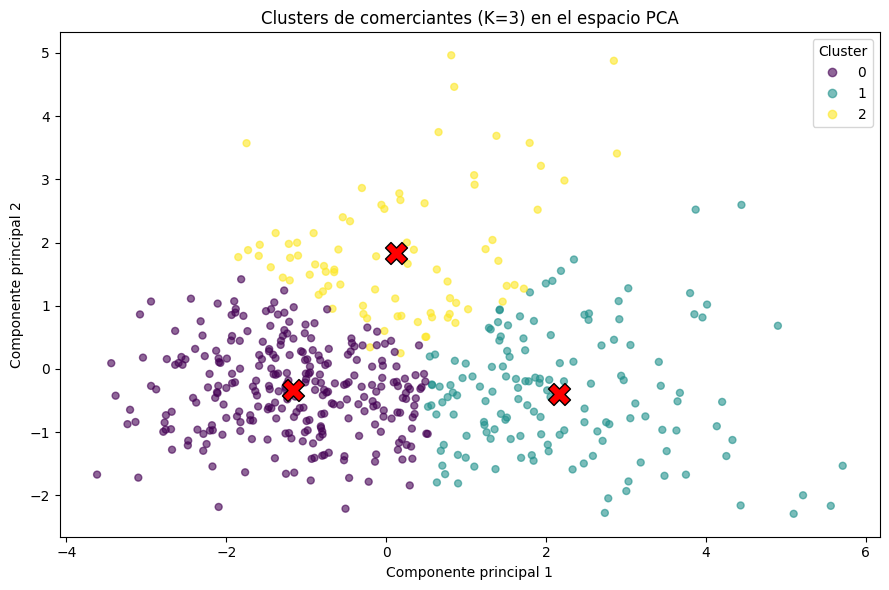

In [24]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2, random_state=42)
Z = pca.fit_transform(X)
C = pca.transform(km.cluster_centers_)
print("Varianza explicada por 2 componentes:", pca.explained_variance_ratio_.sum().round(3))

plt.figure(figsize=(9, 6))
sc = plt.scatter(Z[:, 0], Z[:, 1], c=km.labels_, cmap='viridis', alpha=0.6, s=25)
plt.scatter(C[:, 0], C[:, 1], c='red', marker='X', s=250, edgecolor='black', label='Centroides')
plt.xlabel('Componente principal 1'); plt.ylabel('Componente principal 2')
plt.title(f'Clusters de comerciantes (K={K_FINAL}) en el espacio PCA')
plt.legend(*sc.legend_elements(), title='Cluster', loc='best')
plt.tight_layout()
plt.savefig('output/kmeans_clusters.png', dpi=150)
plt.show()

In [25]:
from scipy.optimize import linear_sum_assignment
from scipy.spatial.distance import cdist

filas = []
for init in ['random', 'k-means++']:
    m = KMeans(n_clusters=K_FINAL, init=init, n_init=10, random_state=42).fit(X)
    filas.append({'init': init, 'inercia': round(m.inertia_, 1), 'iteraciones': m.n_iter_,
                  'silhouette': round(silhouette_score(X, m.labels_), 3)})
display(pd.DataFrame(filas))

ref = km.cluster_centers_
for init in ['random', 'k-means++']:
    inercias, dists = [], []
    for s in range(20):
        m = KMeans(n_clusters=K_FINAL, init=init, n_init=1, random_state=s).fit(X)
        inercias.append(m.inertia_)
        D = cdist(ref, m.cluster_centers_)
        r, c = linear_sum_assignment(D)
        dists.append(D[r, c].mean())
    print(f"{init}: desv. estándar de la inercia = {np.std(inercias):.3f} | "
          f"distancia promedio de centroides vs referencia = {np.mean(dists):.3f}")


,init,inercia,iteraciones,silhouette
0,random,5224.4,13,0.153
1,k-means++,5222.8,11,0.132


random: desv. estándar de la inercia = 27.612 | distancia promedio de centroides vs referencia = 0.904
k-means++: desv. estándar de la inercia = 20.302 | distancia promedio de centroides vs referencia = 0.864
